[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/JPEDROPS092/machine-learning-algorithms/blob/main/notebooks/04-classificador-noticias-naive-bayes.ipynb)

# Classificador de noticias com Naive Bayes

O conjunto e o 20 Newsgroups, lido pelo `fetch_20newsgroups` do scikit-learn. Ficam quatro grupos, com rotulo em portugues para a leitura dos graficos:

| grupo original | rotulo neste caderno |
| --- | --- |
| `rec.sport.hockey` | esporte |
| `talk.politics.misc` | politica |
| `sci.med` | ciencia |
| `comp.graphics` | tecnologia |

Cabecalho, assinatura e citacoes sao removidos (`remove=("headers", "footers", "quotes")`). Sobra o corpo da mensagem. Alguns corpos ficam vazios depois desse corte e sao descartados; a quantidade descartada e impressa.


In [1]:
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    !pip install -q numpy pandas scikit-learn matplotlib seaborn requests
    import os
    if not os.path.isdir("/content/ml-algoritmos/src/mlalgos"):
        !git clone --depth 1 https://github.com/JPEDROPS092/machine-learning-algorithms.git /content/ml-algoritmos
    if "/content/ml-algoritmos/src" not in sys.path:
        sys.path.insert(0, "/content/ml-algoritmos/src")
    PASTA_DADOS = Path("/content/data")
else:
    aqui = Path.cwd().resolve()
    raiz = aqui if (aqui / "src" / "mlalgos").exists() else aqui.parent
    if not (raiz / "src" / "mlalgos").exists():
        raise RuntimeError(
            "Nao encontrei src/mlalgos. Abra o notebook na pasta notebooks ou na raiz do repositorio."
        )
    if str(raiz / "src") not in sys.path:
        sys.path.insert(0, str(raiz / "src"))
    PASTA_DADOS = raiz / "data"

PASTA_DADOS.mkdir(parents=True, exist_ok=True)

%matplotlib inline
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110


def baixar(url, destino):
    """Baixa um arquivo so se ele ainda nao estiver na pasta data, que nao entra no git."""
    destino = Path(destino)
    if destino.exists() and destino.stat().st_size > 0:
        return destino
    import requests

    resposta = requests.get(url, timeout=180, headers={"User-Agent": "ml-algoritmos-aula/1.0"})
    resposta.raise_for_status()
    destino.write_bytes(resposta.content)
    return destino


def padronizar(treino, teste):
    """Z-score com media e desvio do treino. O teste usa os mesmos numeros, sem vazar."""
    treino = np.asarray(treino, dtype=float)
    teste = np.asarray(teste, dtype=float)
    media = treino.mean(axis=0)
    desvio = treino.std(axis=0)
    desvio = np.where(desvio == 0, 1.0, desvio)
    return (treino - media) / desvio, (teste - media) / desvio, media, desvio


## 1) Intuição

Uma banca de jornal separa o caderno de esporte, o de politica, o de ciencia e o de tecnologia antes de voce ler o titulo. A separacao usa palavras que quase nao atravessam a fronteira: "gol" nao mora no caderno de medicina, "kernel" nao mora no de esporte. Quatro pilhas, em vez de duas, e a unica novidade em relacao ao filtro de spam. A conta e a mesma, so que agora ha quatro priors e quatro vetores de log-probabilidade.


## 2) Fundamentação matemática

O teorema de Bayes inverte a pergunta. Em vez de perguntar so quao tipico e o texto dentro de uma classe, calculamos a chance da classe depois de ler o texto:

$$
P(y \mid x) = \frac{P(x \mid y)\, P(y)}{P(x)}
$$

- $P(y \mid x)$ e a probabilidade da classe $y$ depois de observar $x$. E a saida do classificador.
- $P(x \mid y)$ e a verossimilhanca: a chance de ver esse texto se a classe for $y$.
- $P(y)$ e o prior, a frequencia da classe antes de olhar o texto.
- $P(x)$ e a evidencia. Ela nao depende de $y$, entao nao muda qual classe ganha. Na hora de decidir, comparamos $P(x \mid y)\,P(y)$.

A hipotese de independencia condicional, a parte ingênua do nome, diz que, dada a classe, uma palavra nao informa a outra:

$$
P(x \mid y) = \prod_{j=1}^{d} P(x_j \mid y)
$$

- $x_j$ e a contagem da palavra $j$.
- $d$ e o tamanho do vocabulario.
- O produto e falso em frases reais ("nao" muda "bom"), mas o erro muitas vezes se reparte e o sinal de cada palavra ainda aponta a classe certa.

No modelo multinomial a probabilidade de uma palavra e a fatia dela nas contagens da classe. A suavizacao de Laplace soma $\alpha$ para uma palavra nunca vista nao zerar o produto inteiro:

$$
\hat{P}(w \mid y) = \frac{n_{y,w} + \alpha}{n_y + \alpha \, |V|}
$$

- $n_{y,w}$ e quantas vezes a palavra $w$ apareceu na classe $y$.
- $n_y$ e a soma de todas as contagens da classe.
- $|V|$ e o numero de palavras do vocabulario.
- $\alpha$ e a forca da suavizacao. Com $\alpha = 1$ ha uma ocorrencia ficticia de cada palavra em cada classe.

Mil probabilidades pequenas, multiplicadas, estouram para zero no computador. O logaritmo transforma o produto em soma:

$$
\log P(y \mid x) \propto \log P(y) + \sum_{j=1}^{d} x_j \, \log \hat{P}(w_j \mid y)
$$

- $\log P(y)$ e o prior em escala de log.
- $x_j \log \hat{P}(w_j \mid y)$ pesa a palavra pela contagem dela neste texto. Palavra ausente entra com zero.
- A classe escolhida e a de maior soma. Para converter as somas em probabilidades que somam 1, subtraimos o log-sum-exp de todas as classes.

Com $K = 4$ classes a soma de log vira um vetor de quatro numeros. A classe prevista e o argmax. A probabilidade de cada classe sai do log-sum-exp das quatro somas, e as quatro probabilidades somam 1. Nao existe uma unica "classe positiva": precisao, revocacao e F1 sao a media macro, uma medida por classe e depois a media simples, para uma classe pequena nao sumir atras da grande.


## 3) Visualização


train documentos 2243 vazios removidos 56


test documentos 1494 vazios removidos 35


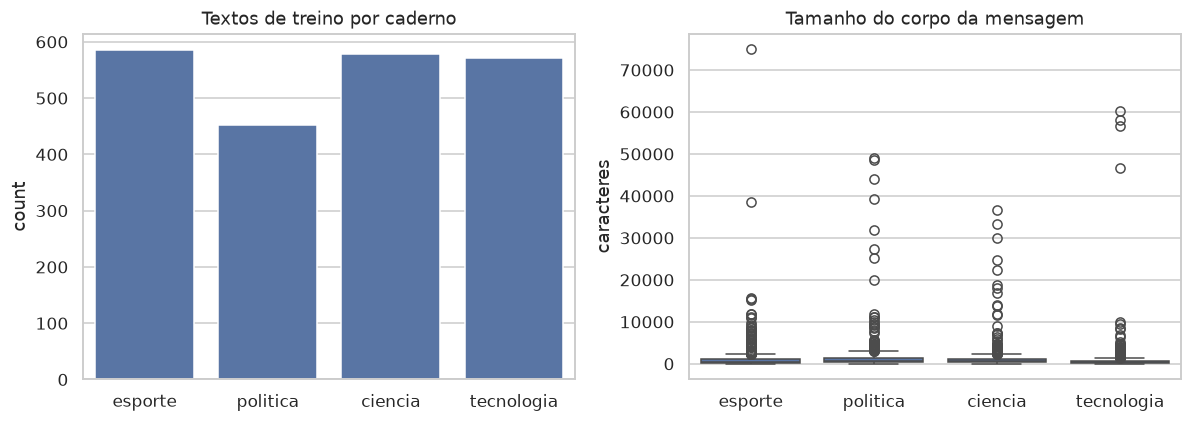

In [2]:
from sklearn.datasets import fetch_20newsgroups

mapa = {
    "rec.sport.hockey": "esporte",
    "talk.politics.misc": "politica",
    "sci.med": "ciencia",
    "comp.graphics": "tecnologia",
}
categorias = list(mapa)

def carregar(subset):
    dados = fetch_20newsgroups(
        subset=subset,
        categories=categorias,
        remove=("headers", "footers", "quotes"),
        shuffle=True,
        random_state=0,
    )
    textos = list(dados.data)
    rotulos = np.array([mapa[dados.target_names[i]] for i in dados.target])
    vazios = np.array([len(t.strip()) == 0 for t in textos])
    print(subset, "documentos", len(textos), "vazios removidos", int(vazios.sum()))
    textos = [t for t, vazio in zip(textos, vazios) if not vazio]
    return textos, rotulos[~vazios]

X_treino_txt, y_treino = carregar("train")
X_teste_txt, y_teste = carregar("test")

df = pd.DataFrame({"classe": y_treino, "tamanho": [len(t) for t in X_treino_txt]})
fig, eixos = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(data=df, x="classe", order=["esporte", "politica", "ciencia", "tecnologia"], ax=eixos[0], color="#4c72b0")
eixos[0].set_title("Textos de treino por caderno")
eixos[0].set_xlabel("")
sns.boxplot(data=df, x="classe", y="tamanho", order=["esporte", "politica", "ciencia", "tecnologia"], ax=eixos[1])
eixos[1].set_title("Tamanho do corpo da mensagem")
eixos[1].set_ylabel("caracteres")
eixos[1].set_xlabel("")
plt.tight_layout()
plt.show()


## 4) Implementação do zero

O modelo continua multinomial. A unica diferenca visivel no codigo e que `y` tem quatro rotulos em texto. `classes_` guarda a ordem alfabetica desses rotulos, e as linhas de `feature_log_prob_` seguem essa ordem.


classes [np.str_('ciencia'), np.str_('esporte'), np.str_('politica'), np.str_('tecnologia')] matriz (2187, 4000)


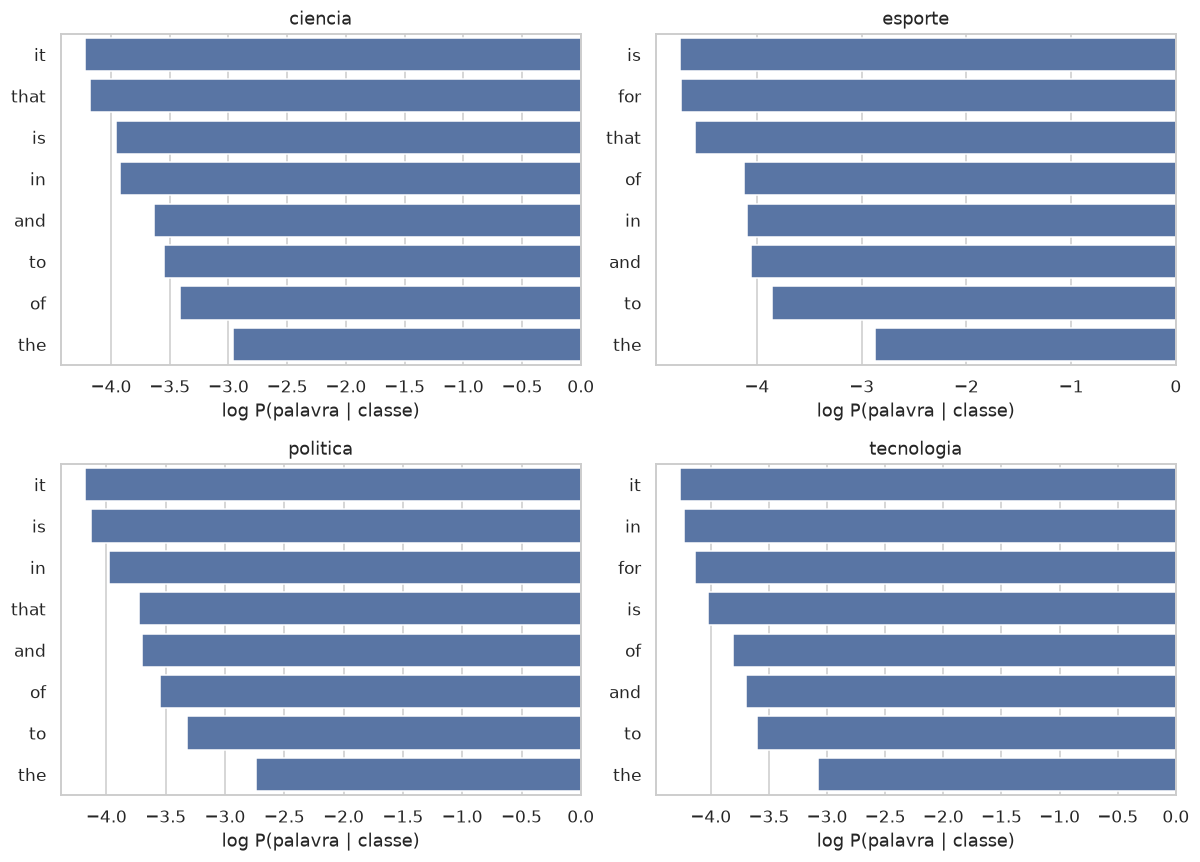

In [3]:
from mlalgos import BagOfWords, MultinomialNB

vetor = BagOfWords(max_features=4000)
X_treino = vetor.fit_transform(X_treino_txt)
X_teste = vetor.transform(X_teste_txt)
nb = MultinomialNB(alpha=1.0).fit(X_treino, y_treino)
print("classes", list(nb.classes_), "matriz", X_treino.shape)

vocabulario = np.empty(len(vetor.vocabulary_), dtype=object)
for token, coluna in vetor.vocabulary_.items():
    vocabulario[coluna] = token

fig, eixos = plt.subplots(2, 2, figsize=(11, 8))
for ax, classe in zip(eixos.ravel(), nb.classes_):
    linha = list(nb.classes_).index(classe)
    topo = np.argsort(nb.feature_log_prob_[linha])[-8:]
    sns.barplot(x=nb.feature_log_prob_[linha][topo], y=vocabulario[topo], ax=ax, color="#4c72b0")
    ax.set_title(classe)
    ax.set_xlabel("log P(palavra | classe)")
plt.tight_layout()
plt.show()


## 5) Implementação com scikit-learn


In [4]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB as SkMultinomialNB
from sklearn.pipeline import Pipeline

sk = SkMultinomialNB(alpha=1.0).fit(X_treino, y_treino)
diferenca = np.max(np.abs(nb.predict_log_proba(X_teste) - sk.predict_log_proba(X_teste)))
acordo = float(np.mean(nb.predict(X_teste) == sk.predict(X_teste)))
print(f"maior diferenca absoluta entre log-probabilidades: {diferenca:.3e}")
print(f"concordancia das classes previstas: {acordo:.3f}")

cano = Pipeline([
    ("contagem", CountVectorizer(max_features=4000)),
    ("nb", SkMultinomialNB(alpha=1.0)),
])
cano.fit(X_treino_txt, y_treino)
print("acuracia do pipeline no teste", float(cano.score(X_teste_txt, y_teste)))


maior diferenca absoluta entre log-probabilidades: 2.842e-14
concordancia das classes previstas: 1.000


acuracia do pipeline no teste 0.8875942426319396


## 6) Avaliação

Nao ha uma classe positiva unica, entao nao ha uma ROC binaria. A ROC-AUC reportada e a media macro um-contra-o-resto: cada classe vira "positiva" na sua vez, com a coluna correspondente de `predict_proba`.


acuracia 0.888 | baseline da classe majoritaria 0.267
precisao macro 0.889 | revocacao macro 0.889 | f1 macro 0.887 | roc_auc macro 0.976
RESUMO_METRICAS {"modelo": "multinomial_nb_20newsgroups", "acuracia": 0.888279643591501, "precisao_macro": 0.8892708999976298, "revocacao_macro": 0.8888557973925665, "f1_macro": 0.8866075655270965, "roc_auc_macro": 0.9756637081881664, "baseline_majoritaria": 0.2673063742289239}


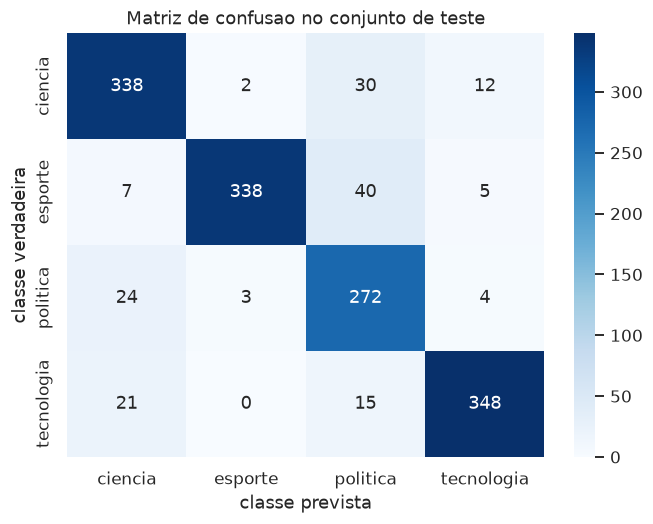

In [5]:
from mlalgos.metrics import confusion_matrix, f1_score, precision_score, recall_score, roc_auc_score

y_previsto = nb.predict(X_teste)
y_proba = nb.predict_proba(X_teste)
acuracia = float(np.mean(y_previsto == y_teste))
precisao = precision_score(y_teste, y_previsto, average="macro")
revocacao = recall_score(y_teste, y_previsto, average="macro")
f1 = f1_score(y_teste, y_previsto, average="macro")
auc = roc_auc_score(y_teste, y_proba, average="macro")
frequencias = pd.Series(y_teste).value_counts(normalize=True)
baseline = float(frequencias.max())
print(f"acuracia {acuracia:.3f} | baseline da classe majoritaria {baseline:.3f}")
print(f"precisao macro {precisao:.3f} | revocacao macro {revocacao:.3f} | f1 macro {f1:.3f} | roc_auc macro {auc:.3f}")
print("RESUMO_METRICAS " + json.dumps({
    "modelo": 'multinomial_nb_20newsgroups',
    "acuracia": acuracia,
    "precisao_macro": precisao,
    "revocacao_macro": revocacao,
    "f1_macro": f1,
    "roc_auc_macro": auc,
    "baseline_majoritaria": baseline,
}))

ordem = list(nb.classes_)
cm = confusion_matrix(y_teste, y_previsto, labels=ordem)
fig, ax = plt.subplots(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=ordem, yticklabels=ordem, ax=ax)
ax.set_xlabel("classe prevista")
ax.set_ylabel("classe verdadeira")
ax.set_title("Matriz de confusao no conjunto de teste")
plt.show()


## 7) Desafios

1. Troque `sci.med` por `sci.space` e veja quais palavras passam a sustentar o rotulo de ciencia.
2. Sem `remove=("headers", "footers", "quotes")` o modelo enxerga o cabecalho do e-mail, inclusive o nome do grupo. Meça o salto de acuracia e explique por que esse salto e trapaça.
3. Escreva tres frases curtas, uma de cada assunto, e peca `predict_proba`. Onde a probabilidade fica espalhada entre duas classes, e por que?
